In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, Model
from sklearn.model_selection import train_test_split
from skimage.metrics import structural_similarity as ssim

np.random.seed(42)
tf.random.set_seed(42)

(x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

x_train, x_val = train_test_split(
    x_train,
    test_size=0.1,
    random_state=42
)

print("Training:", x_train.shape)
print("Validation:", x_val.shape)
print("Test:", x_test.shape)
print("Pixel range:", x_train.min(), x_train.max())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training: (54000, 28, 28, 1)
Validation: (6000, 28, 28, 1)
Test: (10000, 28, 28, 1)
Pixel range: 0.0 1.0


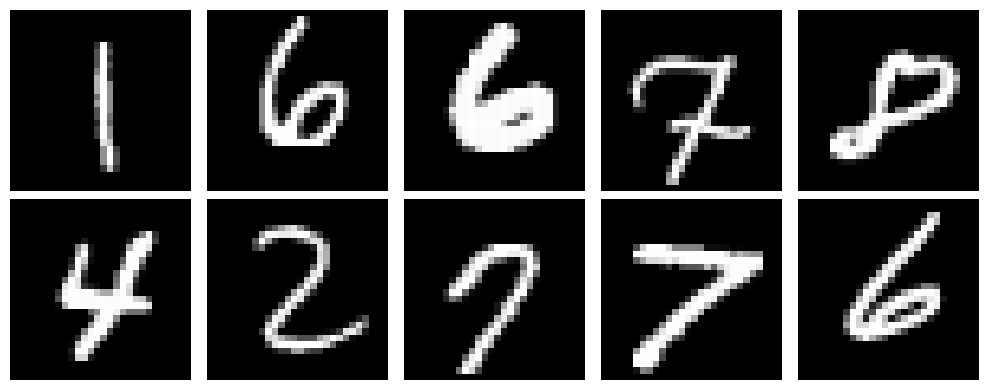

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for ax, image in zip(axes.ravel(), x_train[:10]):
    ax.imshow(image.squeeze(), cmap="gray")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
x_train_flat = x_train.reshape(len(x_train), 784)
x_val_flat = x_val.reshape(len(x_val), 784)
x_test_flat = x_test.reshape(len(x_test), 784)

print(x_train_flat.shape)
print(x_val_flat.shape)
print(x_test_flat.shape)

(54000, 784)
(6000, 784)
(10000, 784)


In [5]:
input_layer = layers.Input(shape=(784,))

x = layers.Dense(128, activation="relu")(input_layer)
x = layers.Dense(32, activation="relu")(x)

latent = layers.Dense(16, activation="relu", name="latent")(x)

x = layers.Dense(32, activation="relu")(latent)
x = layers.Dense(128, activation="relu")(x)

output_layer = layers.Dense(784, activation="sigmoid")(x)

fc_autoencoder = Model(input_layer, output_layer)

fc_autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy"
)

fc_autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 211,040 (824.38 KB)

 Trainable params: 211,040 (824.38 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
history_fc = fc_autoencoder.fit(
    x_train_flat,
    x_train_flat,
    validation_data=(x_val_flat, x_val_flat),
    epochs=20,
    batch_size=128,
    shuffle=True
)

Epoch 1/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - loss: 0.2239 - val_loss: 0.1665
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1561 - val_loss: 0.1481
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1416 - val_loss: 0.1374
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.1342 - val_loss: 0.1322
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1303 - val_loss: 0.1290
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1277 - val_loss: 0.1268
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1255 - val_loss: 0.1248
Epoch 8/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1237 - val_loss: 0.1233
Epoch 9/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1223 - val_loss: 0.1220
Epoch 10/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1211 - val_loss: 0.1210
Epoch 11/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1197 - val_loss: 0.1192
Epoch 12/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

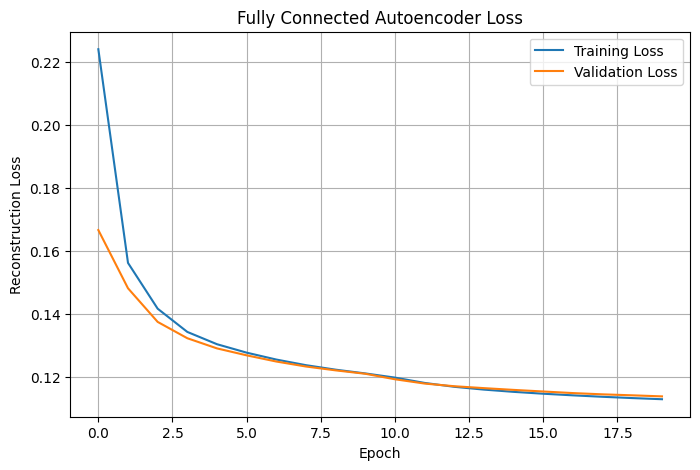

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(history_fc.history["loss"], label="Training Loss")
plt.plot(history_fc.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Reconstruction Loss")
plt.title("Fully Connected Autoencoder Loss")
plt.legend()
plt.grid()
plt.show()

In [8]:
fc_reconstructed_flat = fc_autoencoder.predict(
    x_test_flat,
    verbose=0
)

fc_reconstructed = fc_reconstructed_flat.reshape(
    -1, 28, 28, 1
)

print("Original shape:", x_test.shape)
print("Reconstructed shape:", fc_reconstructed.shape)

Original shape: (10000, 28, 28, 1)
Reconstructed shape: (10000, 28, 28, 1)


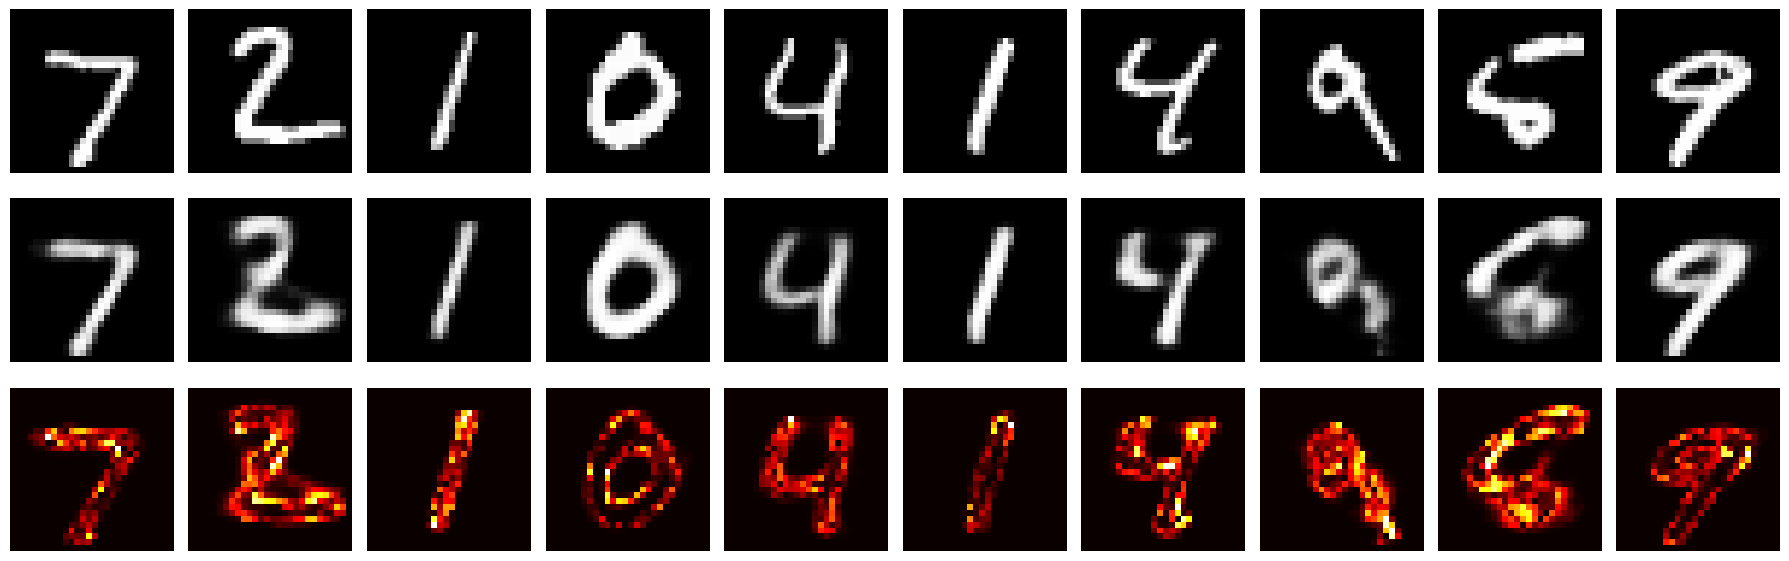

In [9]:
n = 10

fig, axes = plt.subplots(3, n, figsize=(18, 6))

for i in range(n):
    original = x_test[i].squeeze()
    reconstructed = fc_reconstructed[i].squeeze()
    error = np.abs(original - reconstructed)

    axes[0, i].imshow(original, cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(reconstructed, cmap="gray")
    axes[1, i].axis("off")

    axes[2, i].imshow(error, cmap="hot")
    axes[2, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=12)
axes[1, 0].set_ylabel("Reconstructed", fontsize=12)
axes[2, 0].set_ylabel("Error", fontsize=12)

plt.tight_layout()
plt.show()

In [10]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

fc_mse = mean_squared_error(
    x_test_flat,
    fc_reconstructed_flat
)

fc_mae = mean_absolute_error(
    x_test_flat,
    fc_reconstructed_flat
)

print("FC Autoencoder MSE:", fc_mse)
print("FC Autoencoder MAE:", fc_mae)

FC Autoencoder MSE: 0.016617432236671448
FC Autoencoder MAE: 0.04734351858496666


In [11]:
fc_ssim_scores = []

for i in range(len(x_test)):
    score = ssim(
        x_test[i].squeeze(),
        fc_reconstructed[i].squeeze(),
        data_range=1.0
    )
    fc_ssim_scores.append(score)

fc_ssim = np.mean(fc_ssim_scores)

print("FC Autoencoder Mean SSIM:", fc_ssim)

FC Autoencoder Mean SSIM: 0.8145858825399895


In [12]:
input_layer = layers.Input(shape=(28, 28, 1))

x = layers.Conv2D(
    32, 3, activation="relu", padding="same"
)(input_layer)

x = layers.MaxPooling2D(
    2, padding="same"
)(x)

x = layers.Conv2D(
    64, 3, activation="relu", padding="same"
)(x)

x = layers.MaxPooling2D(
    2, padding="same"
)(x)

x = layers.Conv2D(
    64, 3, activation="relu", padding="same"
)(x)

x = layers.UpSampling2D(2)(x)

x = layers.Conv2D(
    32, 3, activation="relu", padding="same"
)(x)

x = layers.UpSampling2D(2)(x)

output_layer = layers.Conv2D(
    1, 3, activation="sigmoid", padding="same"
)(x)

conv_autoencoder = Model(input_layer, output_layer)

conv_autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy"
)

conv_autoencoder.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,497 (291.00 KB)

 Trainable params: 74,497 (291.00 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
history_conv = conv_autoencoder.fit(
    x_train,
    x_train,
    validation_data=(x_val, x_val),
    epochs=20,
    batch_size=128,
    shuffle=True
)

Epoch 1/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - loss: 0.1052 - val_loss: 0.0748
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0723 - val_loss: 0.0708
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0697 - val_loss: 0.0692
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0684 - val_loss: 0.0680
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0674 - val_loss: 0.0673
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0668 - val_loss: 0.0667
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0662 - val_loss: 0.0661
Epoch 8/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0658 - val_loss: 0.0657
Epoch 9/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0654 - val_loss: 0.0654
Epoch 10/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0651 - val_loss: 0.0651
Epoch 11/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0648 - val_loss: 0.0648
Epoch 12/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/st

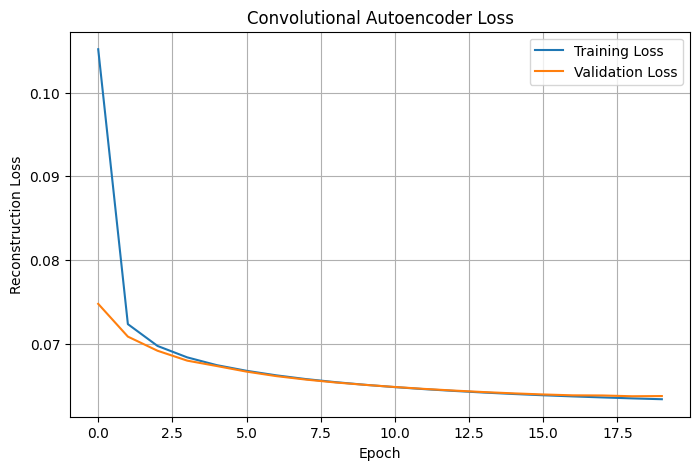

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_conv.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_conv.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Reconstruction Loss")
plt.title("Convolutional Autoencoder Loss")
plt.legend()
plt.grid()
plt.show()

In [16]:
conv_reconstructed = conv_autoencoder.predict(
    x_test,
    verbose=0
)

print("Original shape:", x_test.shape)
print("Reconstructed shape:", conv_reconstructed.shape)

Original shape: (10000, 28, 28, 1)
Reconstructed shape: (10000, 28, 28, 1)


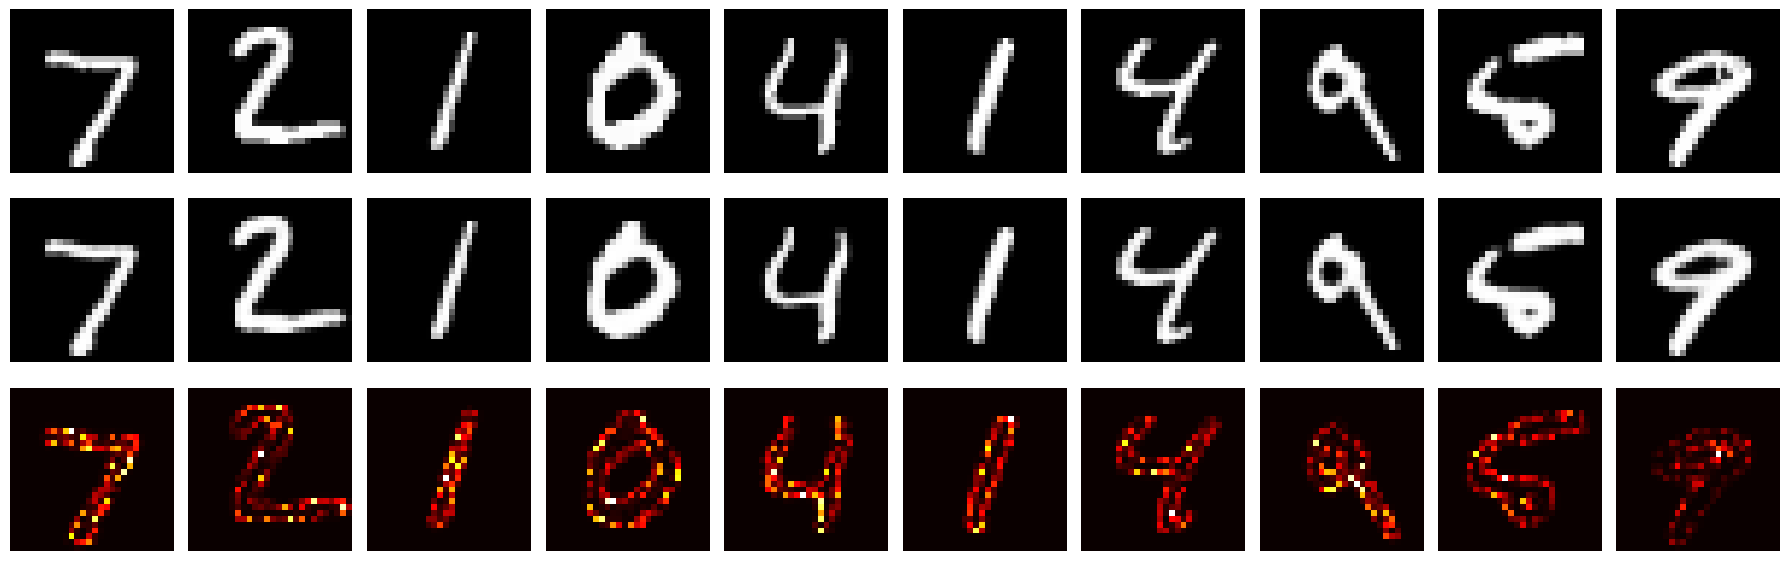

In [17]:
n = 10

fig, axes = plt.subplots(3, n, figsize=(18, 6))

for i in range(n):
    original = x_test[i].squeeze()
    reconstructed = conv_reconstructed[i].squeeze()
    error = np.abs(original - reconstructed)

    axes[0, i].imshow(original, cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(reconstructed, cmap="gray")
    axes[1, i].axis("off")

    axes[2, i].imshow(error, cmap="hot")
    axes[2, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=12)
axes[1, 0].set_ylabel("Reconstructed", fontsize=12)
axes[2, 0].set_ylabel("Error", fontsize=12)

plt.tight_layout()
plt.show()

In [18]:
conv_mse = mean_squared_error(
    x_test.reshape(len(x_test), -1),
    conv_reconstructed.reshape(len(conv_reconstructed), -1)
)

print("Convolutional Autoencoder MSE:", conv_mse)

Convolutional Autoencoder MSE: 0.0012093055993318558


In [19]:
conv_mae = mean_absolute_error(
    x_test.reshape(len(x_test), -1),
    conv_reconstructed.reshape(len(conv_reconstructed), -1)
)

print("Convolutional Autoencoder MAE:", conv_mae)

Convolutional Autoencoder MAE: 0.010279854759573936


In [20]:
conv_ssim_scores = []

for i in range(len(x_test)):
    score = ssim(
        x_test[i].squeeze(),
        conv_reconstructed[i].squeeze(),
        data_range=1.0
    )
    conv_ssim_scores.append(score)

conv_ssim = np.mean(conv_ssim_scores)

print("Convolutional Autoencoder Mean SSIM:", conv_ssim)

Convolutional Autoencoder Mean SSIM: 0.9885616120296968


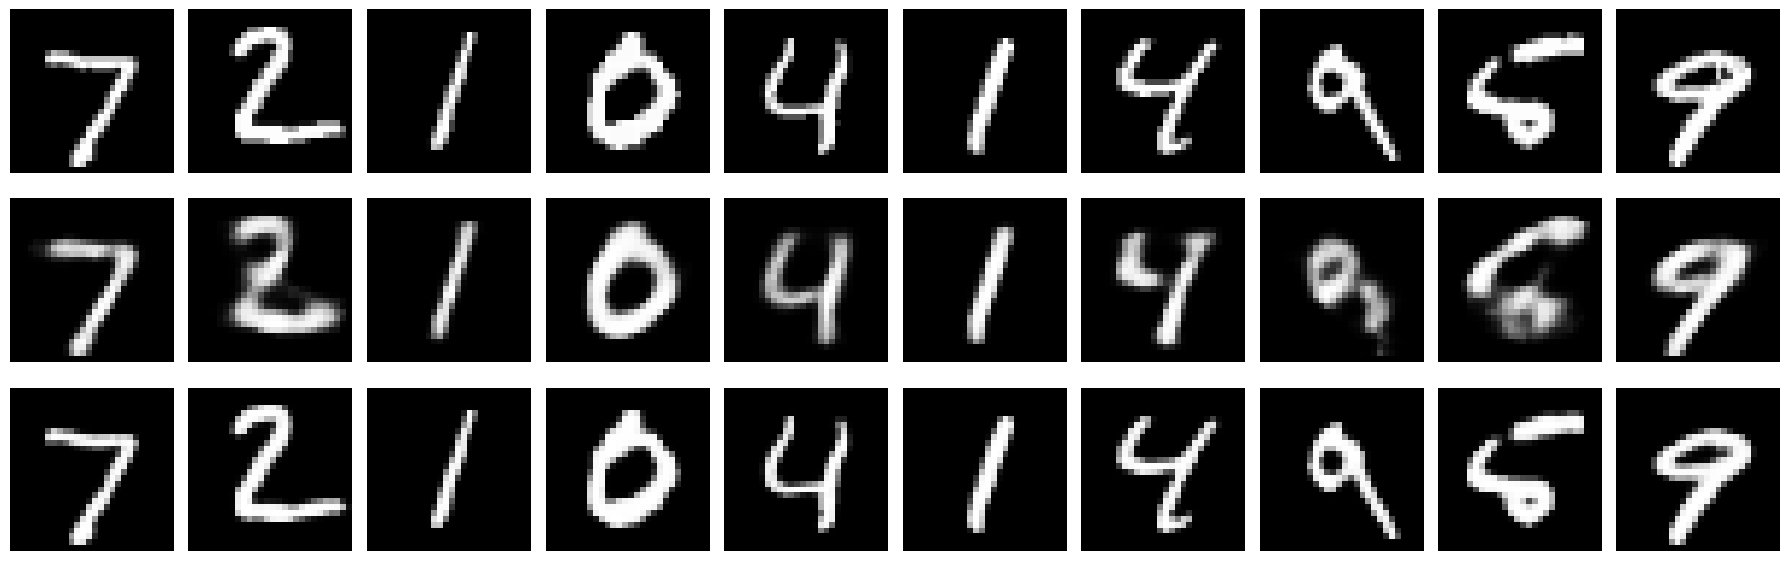

In [21]:
n = 10

fig, axes = plt.subplots(3, n, figsize=(18, 6))

for i in range(n):
    axes[0, i].imshow(
        x_test[i].squeeze(),
        cmap="gray"
    )
    axes[0, i].axis("off")

    axes[1, i].imshow(
        fc_reconstructed[i].squeeze(),
        cmap="gray"
    )
    axes[1, i].axis("off")

    axes[2, i].imshow(
        conv_reconstructed[i].squeeze(),
        cmap="gray"
    )
    axes[2, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=12)
axes[1, 0].set_ylabel("FC-AE", fontsize=12)
axes[2, 0].set_ylabel("CAE", fontsize=12)

plt.tight_layout()
plt.show()

In [22]:
comparison_df = pd.DataFrame({
    "Model": [
        "Fully Connected AE",
        "Convolutional AE"
    ],
    "MSE": [
        fc_mse,
        conv_mse
    ],
    "MAE": [
        fc_mae,
        conv_mae
    ],
    "SSIM": [
        fc_ssim,
        conv_ssim
    ],
    "Parameters": [
        fc_autoencoder.count_params(),
        conv_autoencoder.count_params()
    ]
})

comparison_df

,Model,MSE,MAE,SSIM,Parameters
0,Fully Connected AE,0.016617,0.047344,0.814586,211040
1,Convolutional AE,0.001209,0.010280,0.988562,74497
